**Task 1 – Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


**Task 2 – Creating the Dataset**

In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "Student_ID": range(1, 101),
    "Study_Hours": np.random.randint(1, 10, 100),
    "Attendance": np.random.randint(50, 100, 100),
    "Exam_Score": np.random.randint(35, 100, 100)
}

df = pd.DataFrame(data)

print(df.head(10))

   Student_ID  Study_Hours  Attendance  Exam_Score
0           1            7          84          72
1           2            4          86          58
2           3            8          96          45
3           4            5          63          50
4           5            7          52          93
5           6            3          50          37
6           7            7          54          54
7           8            8          75          93
8           9            5          63          70
9          10            4          88          53


**Task 3 – Exploring the Dataset**

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (100, 4)

Column Names:
['Student_ID', 'Study_Hours', 'Attendance', 'Exam_Score']

Data Types:
Student_ID     int64
Study_Hours    int64
Attendance     int64
Exam_Score     int64
dtype: object

Statistical Summary:
       Student_ID  Study_Hours  Attendance  Exam_Score
count  100.000000   100.000000    100.0000  100.000000
mean    50.500000     5.320000     74.5200   66.290000
std     29.011492     2.639559     14.8545   17.418378
min      1.000000     1.000000     50.0000   35.000000
25%     25.750000     3.000000     62.0000   53.000000
50%     50.500000     5.000000     77.0000   66.000000
75%     75.250000     8.000000     86.5000   82.000000
max    100.000000     9.000000     98.0000   98.000000


**Task 4 – Standardizing the Data**

In [4]:
features = ["Study_Hours", "Attendance", "Exam_Score"]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")
print("Standardized data shape:", X_scaled.shape)

Data standardized successfully!
Standardized data shape: (100, 3)


**Task 5 – Applying PCA (Principal Component Analysis)**

In [5]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("PCA applied successfully!")
print("PCA shape:", X_pca.shape)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)

PCA applied successfully!
PCA shape: (100, 3)
Explained Variance Ratio: [0.38591919 0.33051813 0.28356268]


**Task 6 – PCA Scree Plot**

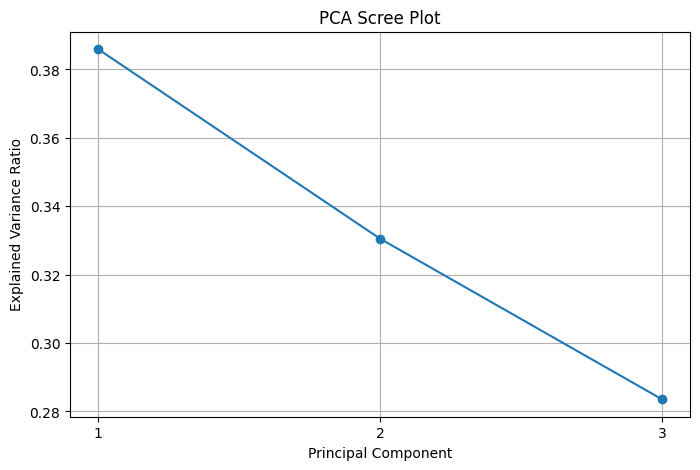

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(pca.explained_variance_ratio_) + 1))
plt.grid(True)

plt.show()

What this graph shows
PC1 → captures the largest amount of information.
PC2 → captures the next largest amount.
PC3 → captures the remaining information.
The scree plot helps us decide how many components to retain.

**Task 7 – Explained Variance (Cumulative) **

In [7]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print("Individual Explained Variance:")
print(pca.explained_variance_ratio_)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Individual Explained Variance:
[0.38591919 0.33051813 0.28356268]

Cumulative Explained Variance:
[0.38591919 0.71643732 1.        ]


What this means
Individual variance → information captured by each component separately.
Cumulative variance → information captured by components combined.
This helps decide how many principal components we need to retain.

**Task 8 – Selecting the Optimal PCA Components**

In [8]:
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Optimal Number of PCA Components:", n_components)
print("Cumulative Variance:", cumulative_variance[n_components - 1])

Optimal Number of PCA Components: 3
Cumulative Variance: 0.9999999999999998


**Task 9 – Transforming Data Using Selected Components**

In [9]:
pca_final = PCA(n_components=n_components)

X_pca_final = pca_final.fit_transform(X_scaled)

print("Final PCA Transformation Completed!")
print("Reduced Data Shape:", X_pca_final.shape)

Final PCA Transformation Completed!
Reduced Data Shape: (100, 3)


**Task 10 – Finding Optimal Clusters (Elbow Method)**

In [10]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_pca_final)
    wcss.append(kmeans.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[300.00000000000006, 220.44848842856135, 167.08430136195113, 132.58683706865202, 106.51612914884072, 86.83627076640789, 73.91140428173327, 65.88208100502112, 60.96076944178714, 56.652579291662285]


**Task 11 – Plotting the Elbow Graph**

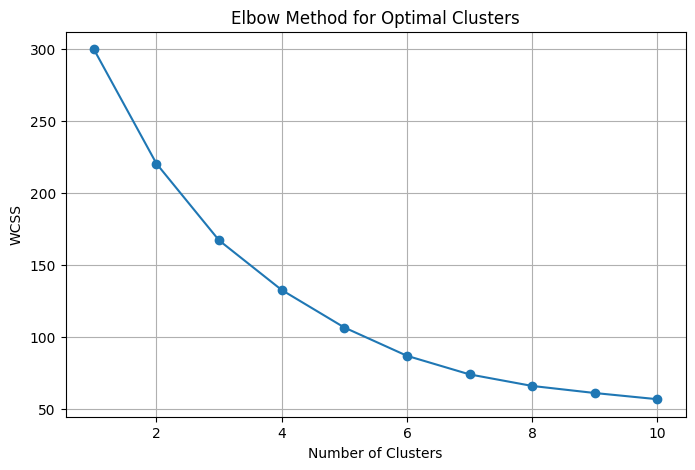

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

**Task 12 – Calculating Silhouette Scores**

In [12]:
silhouette_scores = []

for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_pca_final)

    score = silhouette_score(X_pca_final, labels)
    silhouette_scores.append(score)

    print(f"Clusters: {i}, Silhouette Score: {score:.4f}")

Clusters: 2, Silhouette Score: 0.2508
Clusters: 3, Silhouette Score: 0.2679
Clusters: 4, Silhouette Score: 0.2783
Clusters: 5, Silhouette Score: 0.2973
Clusters: 6, Silhouette Score: 0.3216
Clusters: 7, Silhouette Score: 0.3259
Clusters: 8, Silhouette Score: 0.3185
Clusters: 9, Silhouette Score: 0.3167
Clusters: 10, Silhouette Score: 0.3018


**Task 13 – Visualizing Silhouette Scores**

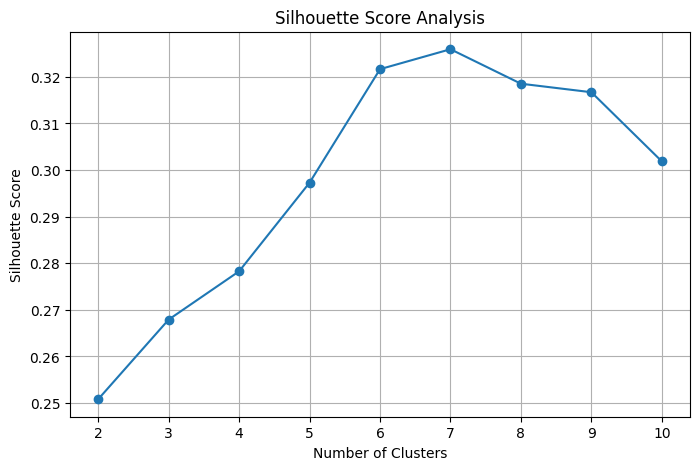

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker="o")

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.show()

**Task 14 – Selecting Optimal Number of Clusters**

In [14]:
best_k = np.argmax(silhouette_scores) + 2

print("Optimal Number of Clusters:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

Optimal Number of Clusters: 7
Best Silhouette Score: 0.32591278126148937


**Task 15 – Performing K-Means Clustering**

In [15]:

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_pca_final)

print("K-Means Clustering Completed!")
print("Cluster Labels:")
print(cluster_labels)

K-Means Clustering Completed!
Cluster Labels:
[4 0 4 5 6 3 5 1 6 0 4 5 6 5 6 2 5 0 2 2 0 5 1 0 0 1 0 5 2 0 2 5 0 5 1 0 3
 4 2 5 0 2 2 4 5 2 3 6 2 4 2 3 0 6 0 5 0 3 3 1 6 4 4 2 2 6 5 4 4 3 4 4 1 1
 2 5 5 2 2 1 3 2 3 6 0 1 4 1 1 6 6 5 4 4 0 6 1 6 3 3]


**Task 16 – Adding Cluster Labels to Dataset**

In [16]:
df["Cluster"] = cluster_labels

print("Cluster labels added successfully!")
print(df.head(10))

Cluster labels added successfully!
   Student_ID  Study_Hours  Attendance  Exam_Score  Cluster
0           1            7          84          72        4
1           2            4          86          58        0
2           3            8          96          45        4
3           4            5          63          50        5
4           5            7          52          93        6
5           6            3          50          37        3
6           7            7          54          54        5
7           8            8          75          93        1
8           9            5          63          70        6
9          10            4          88          53        0


**Task 17 – Cluster Visualization (2D)**

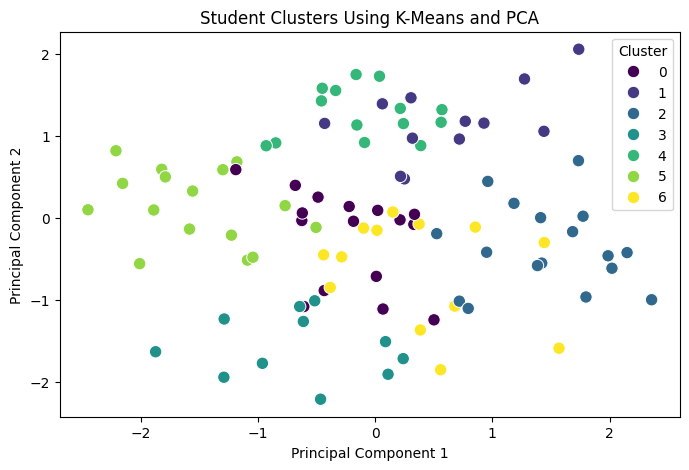

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=df["Cluster"],
    palette="viridis",
    s=80
)

plt.title("Student Clusters Using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

**Task 18 – Analyzing Clusters**








In [18]:
cluster_summary = df.groupby("Cluster")[
    ["Study_Hours", "Attendance", "Exam_Score"]
].mean()

print("Cluster Analysis:")
print(cluster_summary)

Cluster Analysis:
         Study_Hours  Attendance  Exam_Score
Cluster                                     
0           4.000000   82.062500   48.312500
1           8.166667   80.166667   86.083333
2           2.764706   88.647059   79.117647
3           2.272727   58.090909   56.363636
4           8.000000   86.666667   59.933333
5           7.437500   58.125000   52.437500
6           4.538462   61.615385   86.153846


**Task 19 – Final Conclusion**



This project applies Principal Component Analysis (PCA) and K-Means Clustering to student data.

### Key Activities
- Created a dataset containing 100 students.
- Standardized numerical features.
- Applied PCA for dimensionality reduction.
- Created a PCA Scree Plot.
- Used the Elbow Method to identify the optimal number of clusters.
- Calculated Silhouette Scores.
- Applied K-Means Clustering.
- Visualized student clusters using a 2D scatter plot.
- Analyzed cluster characteristics.

### Conclusion
PCA helped transform the dataset into principal components, while K-Means grouped students based on similarities in their study hours, attendance, and exam scores.

The project demonstrates dimensionality reduction and unsupervised machine learning techniques using Python.